# Perbandingan Algoritma Regresi - Dataset Layoffs
Target: `total_laid_off`. Notebook ini membandingkan beberapa algoritma regresi dengan **Pipeline** (tanpa data leakage), **cross validation**, dan metrik **MAE, RMSE, MSE, R²** yang selalu dibandingkan dengan **baseline**.

**Perbaikan dibanding notebook sebelumnya**
1. Baris dengan target kosong di-drop (target tidak boleh diimputasi).
2. Split train/test dilakukan **sebelum** imputasi, scaling, dan encoding (tidak ada leakage).
3. Kolom `source` (URL) dan `company` di-drop karena hampir unik per baris.
4. `date` diubah menjadi `year`, `month`, dan `lag_days`, bukan label encoding teks.
5. Kategori memakai One-Hot Encoding (bukan LabelEncoder), kategori langka digabung.
6. Target yang sangat miring (skewed) dilatih dalam skala `log1p`, lalu metrik dilaporkan di skala asli.

## 1. Import library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load data

In [2]:
raw = pd.read_csv("layoffs.csv")
print(raw.shape)
raw.head()

(4618, 11)


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Blaize,SF Bay Area,NaN,9/30/2026,0.260,AI,https://www.tradingview.com/news/seekingalpha:...,Post-IPO,307.0,United States,10/1/2026
1,Workday,SF Bay Area,525.0,9/29/2026,0.025,HR,https://seekingalpha.com/news/4648205-workday-...,Post-IPO,230.0,United States,10/1/2026
2,Thinkific,"Vancouver, Non-U.S.",96.0,9/23/2026,NaN,Education,https://investors.thinkific.com/2026-09-23-Thi...,Post-IPO,22.0,Canada,9/24/2026
3,Intel,Sacramento,52.0,9/23/2026,NaN,Hardware,https://www.kron4.com/news/technology-ai/intel...,Post-IPO,12.0,United States,9/23/2026
4,Microsoft,Seattle,500.0,9/22/2026,NaN,Other,https://www.businessinsider.com/microsoft-star...,Post-IPO,1.0,United States,9/23/2026


## 3. Pembersihan & feature engineering
Hanya langkah yang **tidak belajar dari data** (parsing tanggal, drop kolom, drop baris target kosong) yang dilakukan di sini. Imputasi, scaling, dan encoding dilakukan di dalam Pipeline.

In [3]:
df = raw.copy()

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["lag_days"] = (df["date_added"] - df["date"]).dt.days

# Target tidak boleh diimputasi: buang baris tanpa target
df = df.dropna(subset=["total_laid_off"])
df = df[df["total_laid_off"] > 0]
df = df.drop_duplicates()

# Drop kolom identitas / URL / tanggal mentah
df = df.drop(columns=["source", "company", "date", "date_added"])

NUM_COLS = ["percentage_laid_off", "funds_raised", "year", "month", "lag_days"]
CAT_COLS = ["location", "industry", "stage", "country"]
TARGET = "total_laid_off"

X = df[NUM_COLS + CAT_COLS]
y = df[TARGET]
print("Jumlah baris setelah cleaning:", len(df))
print(y.describe())

Jumlah baris setelah cleaning: 3016
count     3016.000000
mean       309.614390
std       1111.180438
min          3.000000
25%         40.000000
50%         90.000000
75%        200.000000
max      22000.000000
Name: total_laid_off, dtype: float64


### Distribusi target (skala asli vs log)

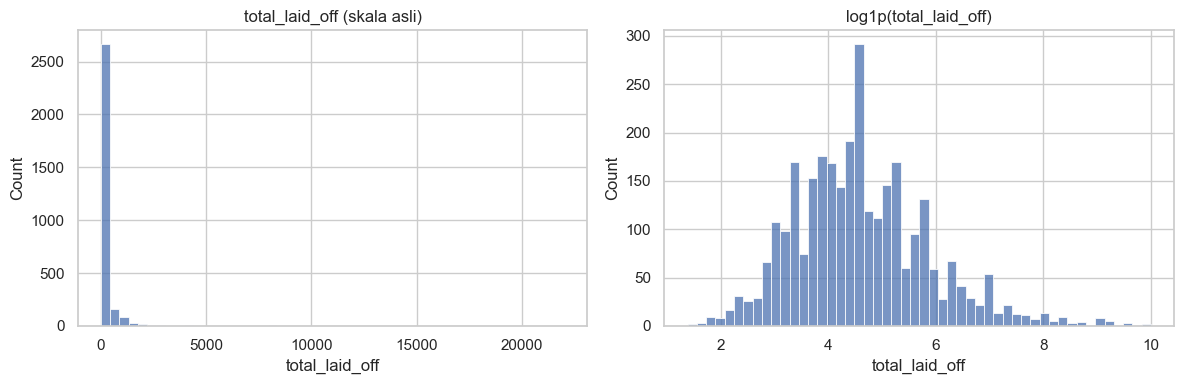

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=50, ax=ax[0]); ax[0].set_title("total_laid_off (skala asli)")
sns.histplot(np.log1p(y), bins=50, ax=ax[1]); ax[1].set_title("log1p(total_laid_off)")
plt.tight_layout(); plt.show()

## 4. Split train / test (dulu), baru preprocessing

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (2412, 9) | Test: (604, 9)


## 5. Preprocessing pipeline

In [6]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),  # indikator missing jadi fitur
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=10, sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, NUM_COLS),
    ("cat", cat_pipe, CAT_COLS),
])

def make_model(regressor, log_target=True):
    """Pipeline lengkap; target dilatih di log1p lalu dikembalikan ke skala asli."""
    if log_target:
        regressor = TransformedTargetRegressor(
            regressor=regressor, func=np.log1p, inverse_func=np.expm1
        )
    return Pipeline([("prep", preprocessor), ("model", regressor)])

## 6. Daftar model
| Model | Peruntukan singkat |
|---|---|
| Baseline (median) | Pembanding wajib: model tidak berguna jika tidak mengalahkan ini |
| Linear / Ridge / Lasso / ElasticNet | Hubungan linear, cepat, mudah dijelaskan (domain sensitif, real-time) |
| Random Forest | Non-linear, interaksi fitur, tahan outlier, data tabular skala menengah |
| Gradient Boosting / HistGradientBoosting | Biasanya akurasi terbaik di data tabular, skala menengah-besar |
| LightGBM / XGBoost (opsional) | Skala besar, inferensi cepat |

In [7]:
models = {
    "Baseline (median)":   make_model(DummyRegressor(strategy="median")),
    "Linear Regression":   make_model(LinearRegression()),
    "Ridge":               make_model(Ridge(alpha=10.0)),
    "Lasso":               make_model(Lasso(alpha=0.01, max_iter=20000)),
    "ElasticNet":          make_model(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000)),
    "Random Forest":       make_model(RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                            n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting":   make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    "HistGradientBoosting": make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}

# Opsional: aktif otomatis jika library terpasang (pip install lightgbm xgboost)
try:
    from lightgbm import LGBMRegressor
    models["LightGBM"] = make_model(LGBMRegressor(n_estimators=300, learning_rate=0.05,
                                                  random_state=RANDOM_STATE, verbose=-1))
except ImportError:
    print("lightgbm tidak terpasang, dilewati")
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = make_model(XGBRegressor(n_estimators=300, learning_rate=0.05,
                                                random_state=RANDOM_STATE))
except ImportError:
    print("xgboost tidak terpasang, dilewati")

list(models)

lightgbm tidak terpasang, dilewati
xgboost tidak terpasang, dilewati


['Baseline (median)',
 'Linear Regression',
 'Ridge',
 'Lasso',
 'ElasticNet',
 'Random Forest',
 'Gradient Boosting',
 'HistGradientBoosting']

## 7. Cross validation (5-fold) + evaluasi di data test
Metrik dihitung di **skala asli** (jumlah karyawan). `R2_log` adalah R² di skala log (lebih adil karena tidak didominasi outlier raksasa).

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

rows = []
for name, pipe in models.items():
    cv = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        "Model": name,
        "CV_MAE": -cv["test_MAE"].mean(),
        "CV_RMSE": -cv["test_RMSE"].mean(),
        "CV_R2": cv["test_R2"].mean(),
        "CV_R2_std": cv["test_R2"].std(),
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_MSE": mean_squared_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test_R2": r2_score(y_test, pred),
        "Test_R2_log": r2_score(np.log1p(y_test), np.log1p(pred)),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("Test_MAE")
base_mae = results.loc["Baseline (median)", "Test_MAE"]
results["MAE_vs_Baseline_%"] = (results["Test_MAE"] / base_mae - 1) * 100  # negatif = lebih baik dari baseline
results.round(3)

### Visualisasi perbandingan

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
results["Test_MAE"].sort_values().plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("Test MAE (lebih kecil lebih baik)")
results["Test_RMSE"].sort_values().plot.barh(ax=ax[1], color="indianred"); ax[1].set_title("Test RMSE (lebih kecil lebih baik)")
results["Test_R2_log"].sort_values().plot.barh(ax=ax[2], color="seagreen"); ax[2].set_title("Test R2 skala log (lebih besar lebih baik)")
plt.tight_layout(); plt.show()

## 8. Hyperparameter tuning pada model terbaik
Contoh dengan `HistGradientBoosting` (cepat dan kuat di data tabular). Ganti `param_dist` bila ingin tuning Random Forest.

In [ ]:
base = make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE))
param_dist = {
    "model__regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__regressor__max_depth": [None, 3, 5, 8],
    "model__regressor__max_leaf_nodes": [8, 15, 31],
    "model__regressor__min_samples_leaf": [5, 10, 20, 40],
    "model__regressor__l2_regularization": [0.0, 0.1, 1.0, 10.0],
}
search = RandomizedSearchCV(base, param_dist, n_iter=25, cv=kf,
                            scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

best = search.best_estimator_
pred_best = best.predict(X_test)
print("Parameter terbaik:", search.best_params_)
print(f"Test MAE : {mean_absolute_error(y_test, pred_best):.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, pred_best)):.2f}")
print(f"Test R2  : {r2_score(y_test, pred_best):.3f}")
print(f"Test R2 (log): {r2_score(np.log1p(y_test), np.log1p(pred_best)):.3f}")
print(f"MAE baseline: {base_mae:.2f}")

## 9. Diagnostik: aktual vs prediksi dan residual

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(np.log1p(y_test), np.log1p(pred_best), alpha=0.4)
lim = [0, max(np.log1p(y_test).max(), np.log1p(pred_best).max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Aktual (log1p)"); ax[0].set_ylabel("Prediksi (log1p)")
ax[0].set_title("Aktual vs Prediksi (skala log)")

resid = np.log1p(y_test) - np.log1p(pred_best)
sns.histplot(resid, kde=True, ax=ax[1]); ax[1].set_title("Distribusi residual (skala log)")
plt.tight_layout(); plt.show()

## 10. Feature importance (permutation, pada fitur asli)

In [ ]:
perm = permutation_importance(best, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(8, 5), color="darkorange")
plt.title("Permutation importance (kenaikan MAE jika fitur diacak)")
plt.show()

## 11. Cara membaca metrik
- **MAE / RMSE / MSE**: tidak ada patokan "harus di bawah 1". Nilainya bergantung skala target, jadi bandingkan dengan **baseline** (kolom `MAE_vs_Baseline_%`). Negatif berarti lebih baik dari baseline.
- **RMSE** satuannya sama dengan target dan lebih sensitif terhadap outlier daripada MAE.
- **R²**: 1 = sempurna, 0 = sama dengan menebak rata-rata, **negatif = lebih buruk dari menebak rata-rata**. Pada data sosial/ekonomi dengan noise tinggi, R² 0,3-0,5 sudah lazim.
- Perhatikan `CV_R2_std` dan selisih CV vs Test. Selisih besar menandakan overfitting atau split yang tidak stabil.

## 12. Panduan memilih algoritma
1. **Jenis data** (numerik/kategorikal, missing value, tabular/teks/gambar/time series)
2. **Ukuran dataset** (ratusan, ribuan, jutaan baris)
3. **Linearitas** hubungan fitur dan target

| Kebutuhan | Pilihan |
|---|---|
| Baseline, data kecil, perlu interpretasi | Linear / Ridge / Lasso / ElasticNet |
| Data tabular non-linear, ukuran menengah | Random Forest, Gradient Boosting |
| Skala besar, butuh inferensi cepat (real-time) | LightGBM / XGBoost, atau linear teregularisasi |
| Domain sensitif (kesehatan, kredit, hukum) | Linear atau tree dangkal; ensemble + SHAP |
| Butuh interval/ketidakpastian | Quantile Regression, Gaussian Process |
| Outlier berat | Huber, RANSAC, Quantile |
| Target berupa hitungan (count) | Poisson / Negative Binomial |
| Hindari untuk real-time | KNN (menyimpan semua data), ensemble yang sangat besar |